In [1]:
# !pip install torchvision

In [2]:
import torch
import os
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from PIL import Image

In [3]:
# images load => transform => dataset of all imgs
class ImageProcessor:
    def __init__(self, root_dir_path, transformations=None):
        self.root_dir_path = root_dir_path
        self.transformations = transformations

        # list of paths for all images
        self.all_img_paths = [os.path.join(root_dir_path, img) for img in os.listdir(root_dir_path)]

    def __len__(self):
        return len(self.all_img_paths)

    def __getitem__(self, idx):
        img_path = self.all_img_paths[idx]
        img = Image.open(img_path).convert("RGB")

        if self.transformations:
            img = self.transformations(img)

        return img

In [5]:
root_dir_path = "./img_align_celeba/img"

transformations = transforms.Compose([
    transforms.CenterCrop(178), # 178x218 => 178x178
    transforms.Resize(64), # 64x64
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) # [-1, 1]
])

In [6]:
dataset = ImageProcessor(root_dir_path, transformations)
print(f"loaded {len(dataset)} images")

loaded 154085 images


In [7]:
dataloader = DataLoader(dataset, batch_size=128, shuffle=True)

In [8]:
import torch.nn as nn
import torch.optim as optim
import numpy as np

In [9]:
class Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=3): # 3 is for RGB
        super(Generator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Linear(z_dim, 256), # 100 => 256
            nn.ReLU(),

            nn.Linear(256, 512), 
            nn.ReLU(),

            nn.Linear(512, 1024), 
            nn.ReLU(),

            nn.Linear(1024, 64 * 64 * img_channels), 
            nn.Tanh() # [-1, 1]
        )

    def forward(self, z):
        img = self.model(z)
        img = img.view(img.size(0), 3, 64, 64) 
        return img

        # fake img => 64 x 64 x 3 x batch_size

In [10]:
class Discriminator(nn.Module):
    def __init__(self, img_channels=3): # 3 is for RGB
        super(Discriminator, self).__init__()

        # fully connected (dense) layers
        self.model = nn.Sequential(
            nn.Flatten(), # 4D tensor => 1D
            
            nn.Linear(img_channels * 64 * 64, 1024),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(1024, 512), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(512, 256), 
            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(256, 1), 
            nn.Sigmoid() # probability of being real/fake 
        )

    def forward(self, img):
        return self.model(img)

In [11]:
GAN_loss = nn.BCELoss()

generator = Generator()
g_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))

discriminator = Discriminator()
d_optimizer = optim.Adam(discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [12]:
import torch
# device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"device is {device}")


device is cpu


In [13]:
generator = generator.to(device)
discriminator = discriminator.to(device)

In [14]:
def train(generator, discriminator, dataloader, epochs=10):

    for epoch in range(epochs):
        for i, imgs in enumerate(dataloader):
            real_imgs = imgs.to(device)
            batch_size = real_imgs.size(0)

            # creates real imgs labels & fake imgs labels
            real_labels = torch.ones(batch_size, 1).to(device) # [1, 1, 1....]
            fake_labels = torch.zeros(batch_size, 1).to(device) # [0, 0, 0....]

            # Train the Discriminator
            d_optimizer.zero_grad()

            fake_imgs = generator(torch.randn(batch_size, 100).to(device))

            real_loss = GAN_loss(discriminator(real_imgs), real_labels)
            fake_loss = GAN_loss(discriminator(fake_imgs.detach()), fake_labels)

            d_loss = (real_loss + fake_loss) / 2

            d_loss.backward()
            d_optimizer.step()

            # Train the Generator
            g_optimizer.zero_grad()

            g_loss = GAN_loss(discriminator(fake_imgs), real_labels)

            g_loss.backward()
            g_optimizer.step()

            if i % 50 == 0:
                print(f"for epoch: {epoch+1}/{epochs}... batch: {i+1}... G-loss:{g_loss}.... D-loss: {d_loss}")

        # save generated imgs for each epoch
        save_generated_images(generator, epoch, device) 

In [15]:
import matplotlib.pyplot as plt
import torchvision

def save_generated_images(generator, epoch, device, num_imgs=8):
    z = torch.randn(num_imgs, 100).to(device)
    generated_imgs = generator(z).detach().cpu()

    grid = torchvision.utils.make_grid(generated_imgs, nrow=4, normalize=True)

    plt.imshow(np.transpose(grid, (1, 2, 0)))
    plt.title(f"epoch {epoch+1}")
    plt.axis("off")
    plt.show()

for epoch: 1/5... batch: 1... G-loss:0.675873875617981.... D-loss: 0.6890485286712646
for epoch: 1/5... batch: 51... G-loss:1.005494475364685.... D-loss: 0.2766963839530945
for epoch: 1/5... batch: 101... G-loss:2.194131374359131.... D-loss: 0.11098849773406982
for epoch: 1/5... batch: 151... G-loss:0.12202005088329315.... D-loss: 1.269755482673645
for epoch: 1/5... batch: 201... G-loss:0.5948326587677002.... D-loss: 0.6177049279212952
for epoch: 1/5... batch: 251... G-loss:0.8155453205108643.... D-loss: 0.3226659893989563
for epoch: 1/5... batch: 301... G-loss:2.4324865341186523.... D-loss: 0.19871343672275543
for epoch: 1/5... batch: 351... G-loss:0.5360943675041199.... D-loss: 0.6156705021858215
for epoch: 1/5... batch: 401... G-loss:2.935108184814453.... D-loss: 0.11200502514839172
for epoch: 1/5... batch: 451... G-loss:1.2950515747070312.... D-loss: 0.17146643996238708
for epoch: 1/5... batch: 501... G-loss:2.3867506980895996.... D-loss: 0.47855979204177856
for epoch: 1/5... batch

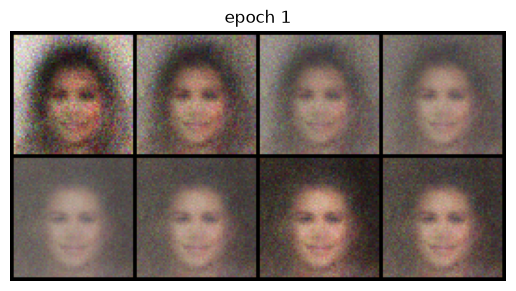

for epoch: 2/5... batch: 1... G-loss:3.5655677318573.... D-loss: 0.1196822077035904
for epoch: 2/5... batch: 51... G-loss:3.7444448471069336.... D-loss: 0.22294855117797852
for epoch: 2/5... batch: 101... G-loss:5.16869592666626.... D-loss: 0.06876601278781891
for epoch: 2/5... batch: 151... G-loss:2.5261151790618896.... D-loss: 0.10329126566648483
for epoch: 2/5... batch: 201... G-loss:4.90798807144165.... D-loss: 0.2715515196323395
for epoch: 2/5... batch: 251... G-loss:3.7564847469329834.... D-loss: 0.1317364126443863
for epoch: 2/5... batch: 301... G-loss:3.185612201690674.... D-loss: 0.1487789750099182
for epoch: 2/5... batch: 351... G-loss:3.0986738204956055.... D-loss: 0.23229354619979858
for epoch: 2/5... batch: 401... G-loss:3.297693967819214.... D-loss: 0.1412735879421234
for epoch: 2/5... batch: 451... G-loss:3.006592035293579.... D-loss: 0.12708218395709991
for epoch: 2/5... batch: 501... G-loss:2.9135901927948.... D-loss: 0.1397274285554886
for epoch: 2/5... batch: 551... 

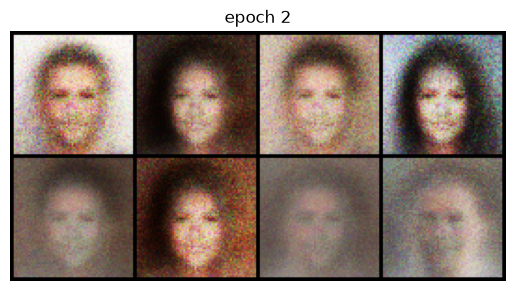

for epoch: 3/5... batch: 1... G-loss:3.0933353900909424.... D-loss: 0.259985089302063
for epoch: 3/5... batch: 51... G-loss:2.9918346405029297.... D-loss: 0.20818734169006348
for epoch: 3/5... batch: 101... G-loss:3.203403949737549.... D-loss: 0.19559943675994873
for epoch: 3/5... batch: 151... G-loss:2.63175106048584.... D-loss: 0.2695874273777008
for epoch: 3/5... batch: 201... G-loss:2.6722474098205566.... D-loss: 0.23679420351982117
for epoch: 3/5... batch: 251... G-loss:3.355233669281006.... D-loss: 0.19009102880954742
for epoch: 3/5... batch: 301... G-loss:3.6633174419403076.... D-loss: 0.3934445381164551
for epoch: 3/5... batch: 351... G-loss:2.465120792388916.... D-loss: 0.2718351185321808
for epoch: 3/5... batch: 401... G-loss:2.4961555004119873.... D-loss: 0.20216090977191925
for epoch: 3/5... batch: 451... G-loss:2.673003673553467.... D-loss: 0.29596203565597534
for epoch: 3/5... batch: 501... G-loss:2.5189366340637207.... D-loss: 0.2753695249557495
for epoch: 3/5... batch: 

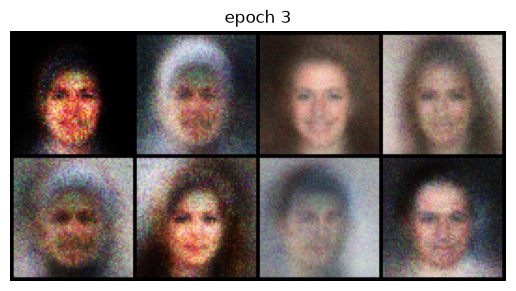

for epoch: 4/5... batch: 1... G-loss:2.6935441493988037.... D-loss: 0.29792147874832153
for epoch: 4/5... batch: 51... G-loss:2.5812110900878906.... D-loss: 0.4024618864059448
for epoch: 4/5... batch: 101... G-loss:2.1173439025878906.... D-loss: 0.37470680475234985
for epoch: 4/5... batch: 151... G-loss:2.58886456489563.... D-loss: 0.2930948734283447
for epoch: 4/5... batch: 201... G-loss:3.0814194679260254.... D-loss: 0.36218273639678955
for epoch: 4/5... batch: 251... G-loss:2.09110689163208.... D-loss: 0.3016064167022705
for epoch: 4/5... batch: 301... G-loss:3.1470139026641846.... D-loss: 0.3410237729549408
for epoch: 4/5... batch: 351... G-loss:2.5982964038848877.... D-loss: 0.35287749767303467
for epoch: 4/5... batch: 401... G-loss:2.290081739425659.... D-loss: 0.331481009721756
for epoch: 4/5... batch: 451... G-loss:2.4755029678344727.... D-loss: 0.37410053610801697
for epoch: 4/5... batch: 501... G-loss:1.9715371131896973.... D-loss: 0.41571393609046936
for epoch: 4/5... batch:

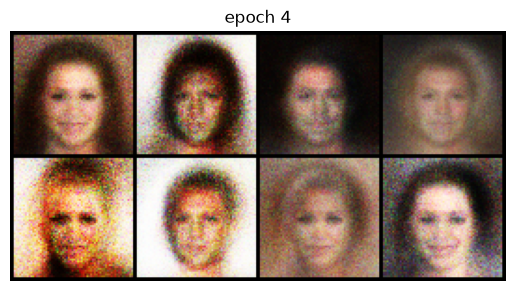

for epoch: 5/5... batch: 1... G-loss:1.8366148471832275.... D-loss: 0.4280856251716614
for epoch: 5/5... batch: 51... G-loss:2.603870153427124.... D-loss: 0.3332553505897522
for epoch: 5/5... batch: 101... G-loss:2.246471643447876.... D-loss: 0.3408006727695465
for epoch: 5/5... batch: 151... G-loss:2.365168333053589.... D-loss: 0.357771635055542
for epoch: 5/5... batch: 201... G-loss:2.1038355827331543.... D-loss: 0.35811829566955566
for epoch: 5/5... batch: 251... G-loss:1.6406348943710327.... D-loss: 0.43024560809135437
for epoch: 5/5... batch: 301... G-loss:2.5073437690734863.... D-loss: 0.44367143511772156


KeyboardInterrupt: 

In [16]:
train(generator, discriminator, dataloader, epochs=5)